In [244]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from math import log2

## 2. Chargement des données
Le dataset est celui de UCI : Predict Students' Dropout and Academic Success.

In [245]:
# Chargement du dataset
df = pd.read_csv("..\data\data.csv", sep=";")

# Nettoyage des espaces dans les noms de colonnes
df.columns = df.columns.str.strip()

# Copie de sécurité
df_original = df.copy()

print("Dimensions du dataset :", df.shape)

display(df.head())

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11096\581714181.py:2: SyntaxWarning: invalid escape sequence '\d'
  df = pd.read_csv("..\data\data.csv", sep=";")


Dimensions du dataset : (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Vérification de la structure :

In [246]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nTypes des variables :")
display(df.dtypes.value_counts())

print("\nInformations générales :")
df.info()

Nombre de lignes : 4424
Nombre de colonnes : 37

Types des variables :


int64      29
float64     7
str         1
Name: count, dtype: int64


Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification    

Vérification de la variable cible :

In [247]:
print("Valeurs de Target :")
print(df["Target"].value_counts())

print("\nPourcentages :")
display(
    df["Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Valeurs de Target :
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Pourcentages :


Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

## 3. Vérification et nettoyage des données

In [248]:
# Vérification des valeurs manquantes
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(df)) * 100
})

display(missing_summary[missing_summary["Missing Values"] > 0])

print("Total des valeurs manquantes :", df.isnull().sum().sum())

,Missing Values,Percentage


Total des valeurs manquantes : 0


Vérification des doublons :

In [249]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


Vérification des lignes et colonnes :

In [250]:
print("Lignes entièrement vides :", df.isnull().all(axis=1).sum())
print("Colonnes entièrement vides :", df.isnull().all(axis=0).sum())

print("Colonnes avec une seule valeur :")
display(df.columns[df.nunique() <= 1].tolist())

Lignes entièrement vides : 0
Colonnes entièrement vides : 0
Colonnes avec une seule valeur :


[]

## 4. Analyse des variables

4.1 Identifier les variables numériques et catégorielles

une variable stockée sous forme d'entier n'est pas nécessairement quantitative.

In [251]:
# Variables catégorielles
categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Variables quantitatives et ordinales
numerical_cols = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Variables académiques quantitatives
academic_cols = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",

    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
]

numerical_cols += academic_cols

# Vérification
print("Variables catégorielles :", len(categorical_cols))
print("Variables numériques :", len(numerical_cols))

print("\nColonnes catégorielles absentes :")
print(set(categorical_cols) - set(df.columns))

print("\nColonnes numériques absentes :")
print(set(numerical_cols) - set(df.columns))

print("\nNombre total de features :", 
      len(categorical_cols) + len(numerical_cols))

Variables catégorielles : 17
Variables numériques : 19

Colonnes catégorielles absentes :
set()

Colonnes numériques absentes :
set()

Nombre total de features : 36


4.2 Vérifier les statistiques descriptives

In [252]:
display(df[numerical_cols].describe().round(2))

,Application order,Previous qualification (grade),Admission grade,Age at enrollment,Unemployment rate,Inflation rate,GDP,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.73,132.61,126.98,23.27,11.57,1.23,0.00,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15
std,1.31,13.19,14.48,7.59,2.66,1.38,2.27,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75
min,0.00,95.00,95.00,17.00,7.60,-0.80,-4.06,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,125.00,117.90,19.00,9.40,0.30,-1.70,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00
50%,1.00,133.10,126.10,20.00,11.10,1.40,0.32,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00
75%,2.00,140.00,134.80,25.00,13.90,2.60,1.79,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00
max,9.00,190.00,190.00,70.00,16.20,3.70,3.51,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00


Pour les variables catégorielles :

In [253]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts().head(20))


--- Marital status ---


Marital status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: int64


--- Application mode ---


Application mode
1     1708
17     872
39     785
43     312
44     213
7      139
18     124
42      77
51      59
16      38
53      35
15      30
5       16
10      10
2        3
57       1
26       1
27       1
Name: count, dtype: int64


--- Course ---


Course
9500    766
9147    380
9238    355
9085    337
9773    331
9991    268
9670    268
9254    252
9070    226
171     215
8014    215
9003    210
9853    192
9119    170
9130    141
9556     86
33       12
Name: count, dtype: int64

... (24 outputs left out)


--- Scholarship holder ---


Scholarship holder
0    3325
1    1099
Name: count, dtype: int64


--- International ---


International
0    4314
1     110
Name: count, dtype: int64

## 5. Analyse des valeurs aberrantes (Outliers)

On utilise la méthode IQR (Interquartile Range).
\[IQR = Q3-Q1\]

\[Lower = Q1-1.5 *times IQR\]

\[Upper = Q3+1.5 *times IQR\]

In [254]:
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outliers_df = pd.DataFrame(outlier_results)

display(
    outliers_df.sort_values(
        by="Outliers Count",
        ascending=False
    ).round(2)
)

,Variable,Lower Bound,Upper Bound,Outliers Count,Percentage
17,Curricular units 2nd sem (grade),6.87,17.21,877,19.82
11,Curricular units 1st sem (grade),7.40,17.00,726,16.41
7,Curricular units 1st sem (credited),0.00,0.00,577,13.04
0,Application order,-0.50,3.50,541,12.23
13,Curricular units 2nd sem (credited),0.00,0.00,530,11.98
3,Age at enrollment,10.00,34.00,441,9.97
8,Curricular units 1st sem (enrolled),2.00,10.00,424,9.58
14,Curricular units 2nd sem (enrolled),2.00,10.00,369,8.34
12,Curricular units 1st sem (without evaluations),0.00,0.00,294,6.65
18,Curricular units 2nd sem (without evaluations),0.00,0.00,282,6.37


### Visualisation

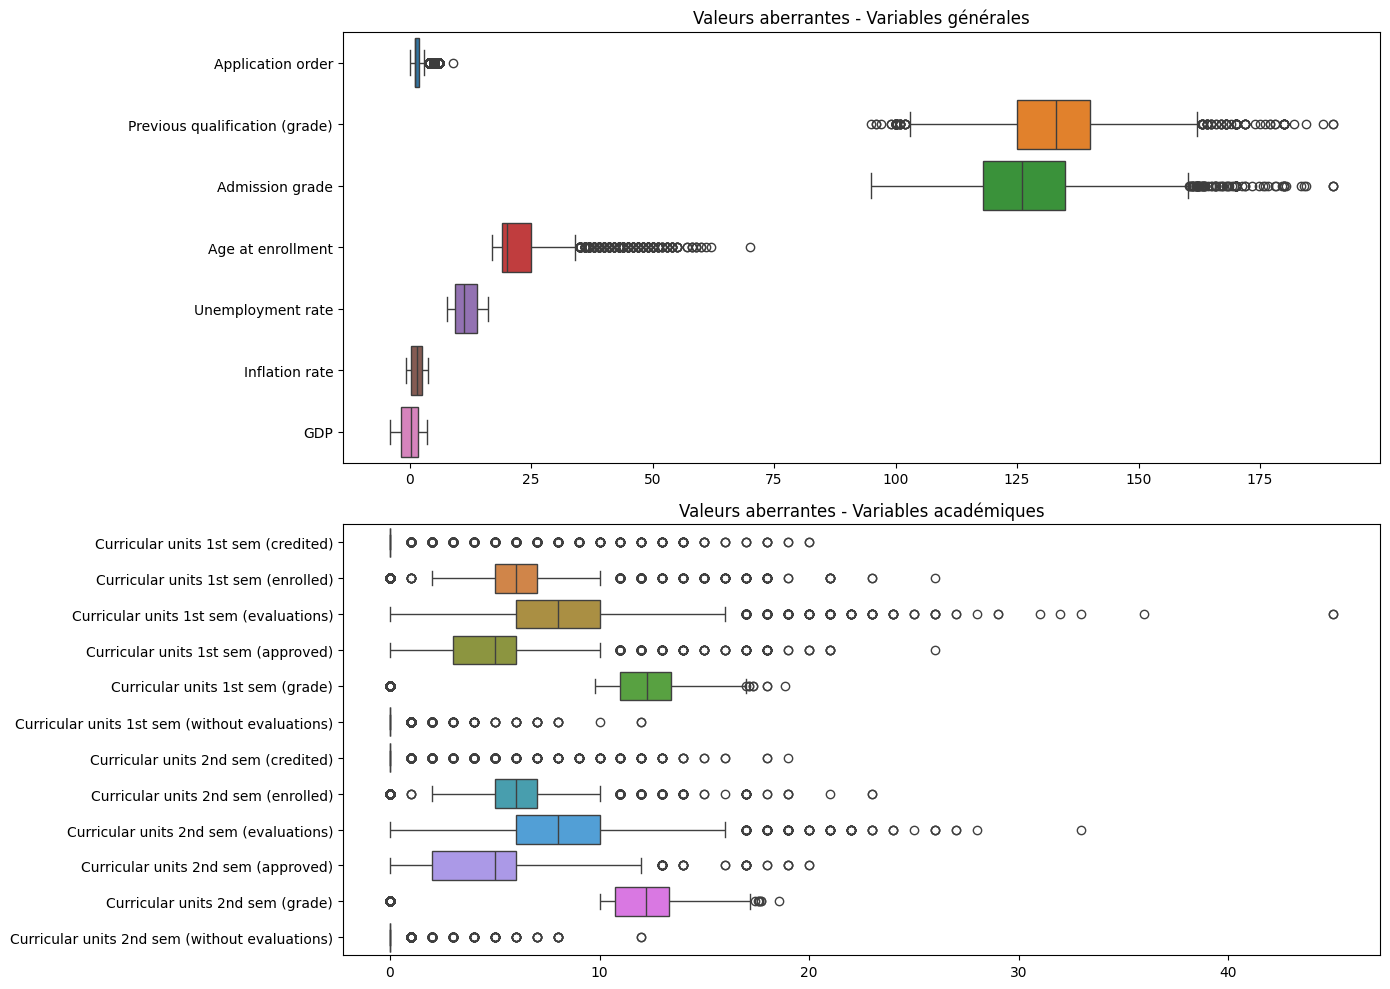

In [255]:
# Variables générales
general_numeric_cols = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

sns.boxplot(data=df[general_numeric_cols], orient="h", ax=axes[0])
axes[0].set_title("Valeurs aberrantes - Variables générales")

sns.boxplot(data=df[academic_cols], orient="h", ax=axes[1])
axes[1].set_title("Valeurs aberrantes - Variables académiques")

plt.tight_layout()
plt.show()

Visualisation des notes

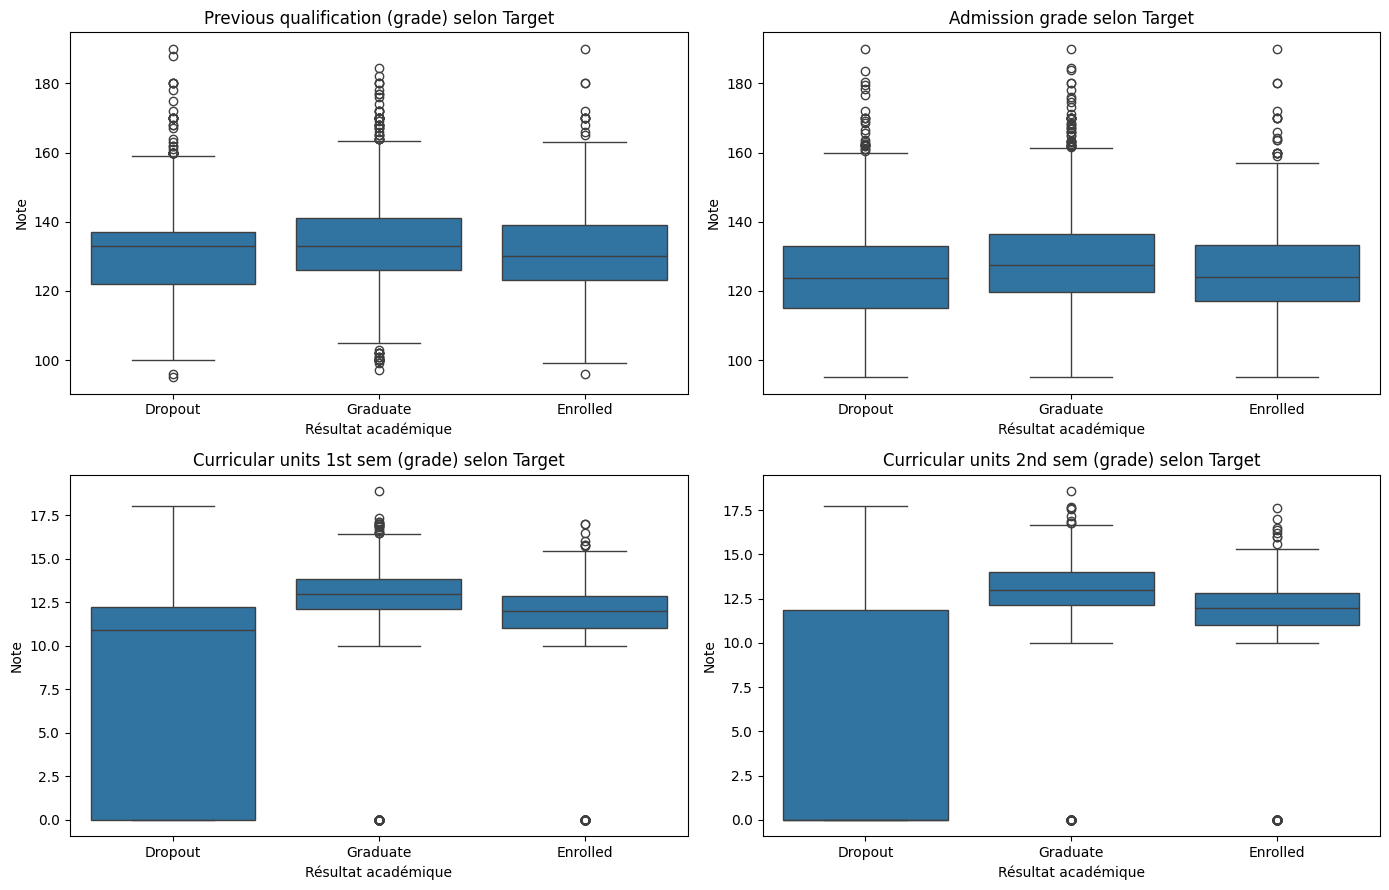

In [256]:
grade_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), grade_cols):
    sns.boxplot(data=df, x="Target", y=col, ax=ax)
    ax.set_title(f"{col} selon Target")
    ax.set_xlabel("Résultat académique")
    ax.set_ylabel("Note")

plt.tight_layout()
plt.show()

## 6. Analyse des relations entre les variables

6.1 Matrice de corrélation

On étudie les corrélations entre les variables quantitatives.

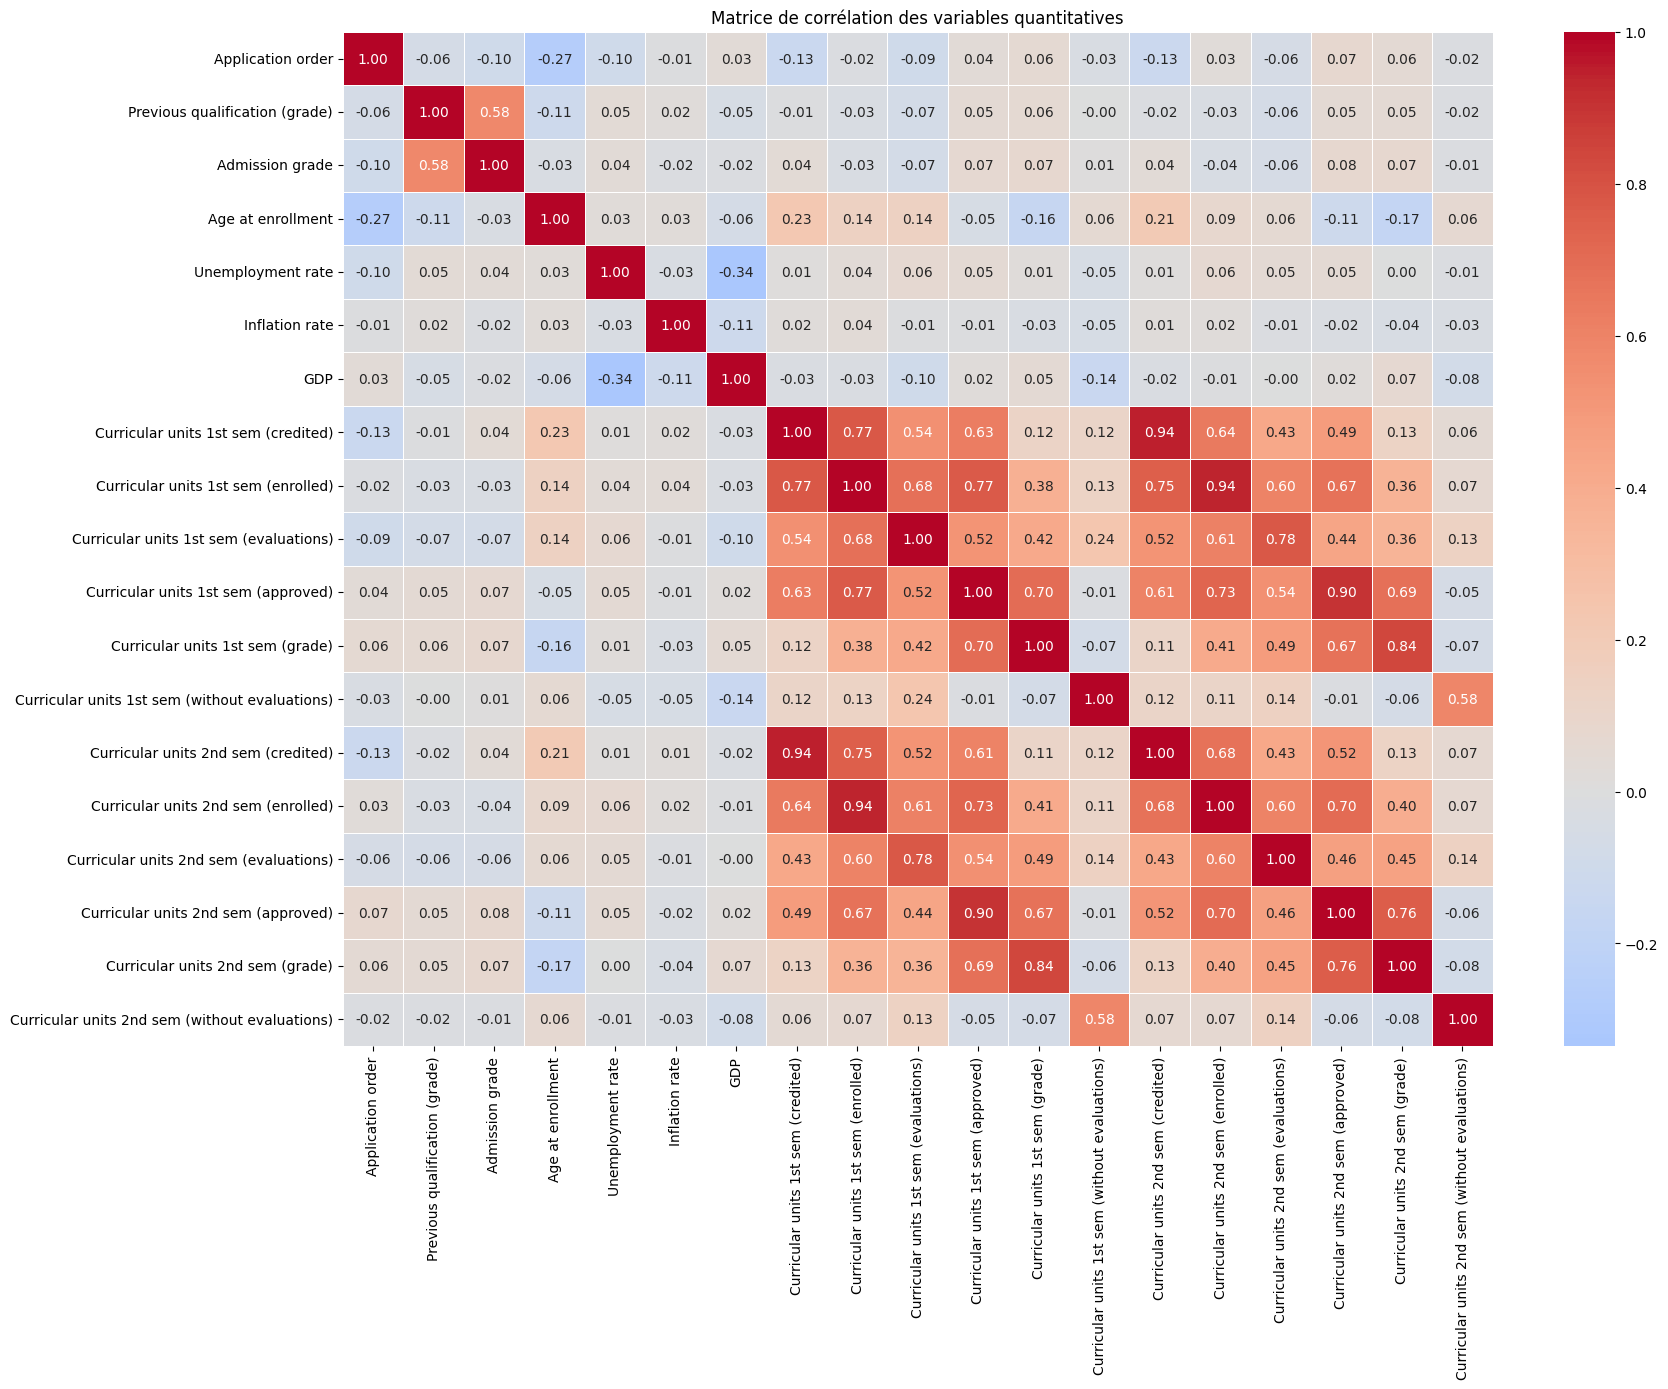

In [257]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

6.2 Relation entre les notes et la variable cible

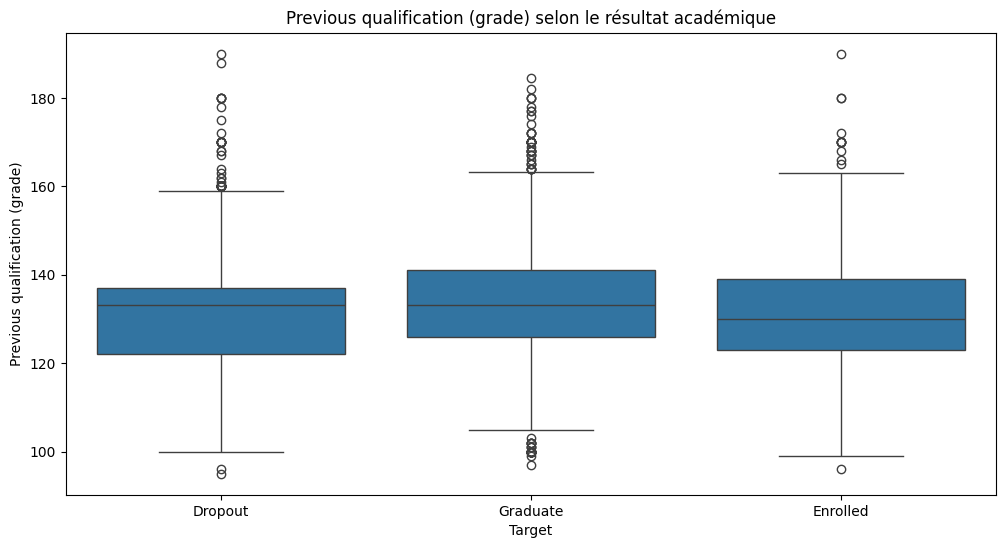

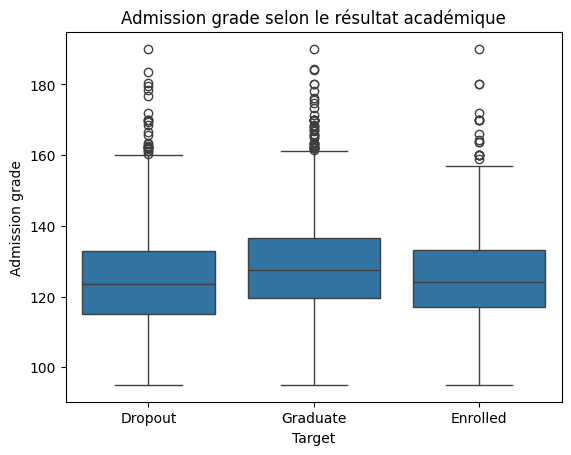

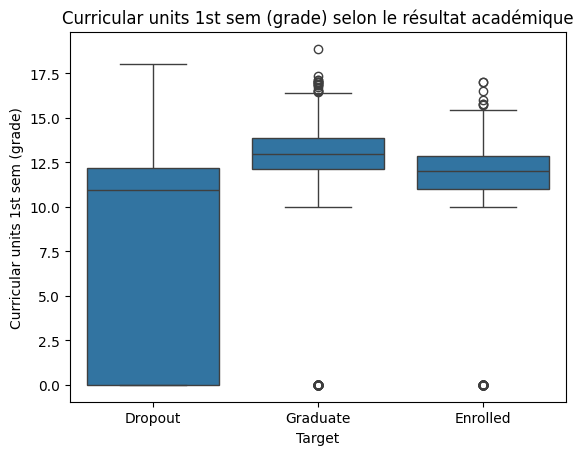

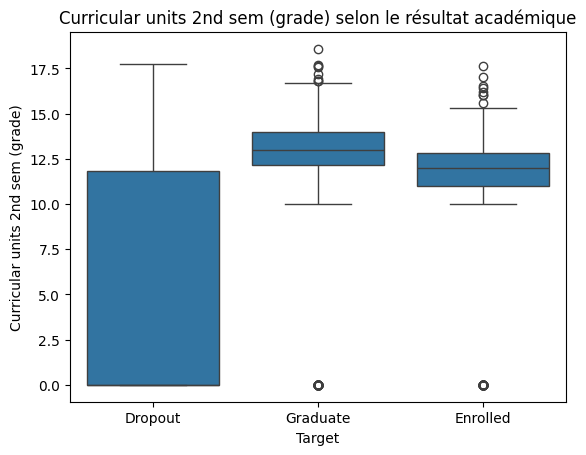

In [258]:
plt.figure(figsize=(12, 6))

for col in grade_cols:
    sns.boxplot(
        data=df,
        x="Target",
        y=col
    )
    plt.title(f"{col} selon le résultat académique")
    plt.show()

6.3 Comparaison des moyennes académiques selon Target

In [259]:
academic_grade_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

grade_comparison = (
    df.groupby("Target")[academic_grade_cols]
    .mean()
    .round(2)
)

display(grade_comparison)

,Previous qualification (grade),Admission grade,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
Target,,,,
Dropout,131.11,124.96,7.26,5.90
Enrolled,131.21,125.53,11.13,11.12
Graduate,134.08,128.79,12.64,12.70


6.4 Comparaison des variables académiques

In [260]:
academic_comparison = (
    df.groupby("Target")[academic_cols]
    .mean()
    .round(2)
)

display(academic_comparison)

,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
Target,,,,,,,,,,,,
Dropout,0.61,5.82,7.75,2.55,7.26,0.19,0.45,5.78,7.17,1.94,5.90,0.24
Enrolled,0.51,5.96,9.34,4.32,11.13,0.18,0.36,5.94,9.44,4.06,11.12,0.19
Graduate,0.85,6.67,8.28,6.23,12.64,0.09,0.67,6.63,8.14,6.18,12.70,0.08


## 7. Vérification de l'équilibre des classes

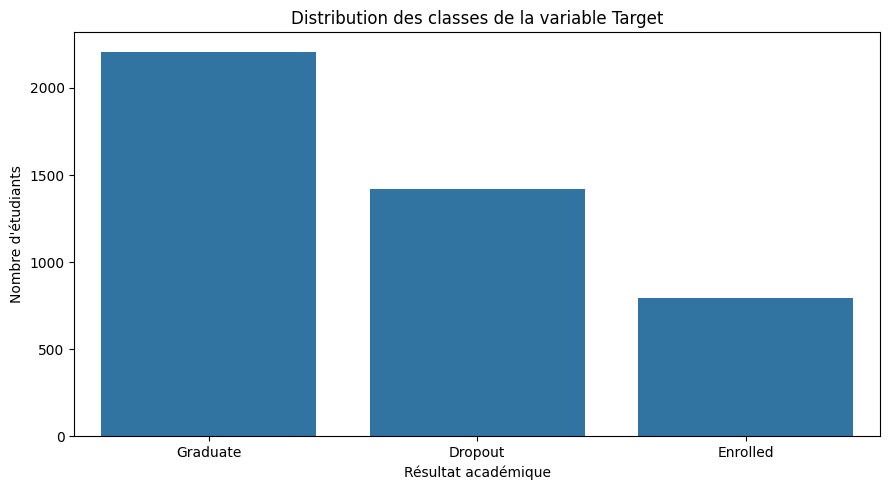

In [261]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Distribution des classes de la variable Target")
plt.xlabel("Résultat académique")
plt.ylabel("Nombre d'étudiants")

plt.tight_layout()
plt.show()

Calcul des proportions :

In [262]:
class_distribution = pd.DataFrame({
    "Effectif": df["Target"].value_counts(),
    "Pourcentage": df["Target"].value_counts(normalize=True) * 100
})

display(class_distribution.round(2))

,Effectif,Pourcentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


## 8. Préparation des données pour le Machine Learning

8.1 Séparation entre X et y

In [263]:
# Variables explicatives
X = df.drop(columns=["Target"])

# Variable cible
y = df["Target"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (4424, 36)
Dimensions de y : (4424,)


8.2 Séparation Train/Test

In [264]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test :", X_test.shape)

print("\nDimensions y_train :", y_train.shape)
print("Dimensions y_test :", y_test.shape)

Dimensions X_train : (3539, 36)
Dimensions X_test : (885, 36)

Dimensions y_train : (3539,)
Dimensions y_test : (885,)


In [265]:
print("Distribution originale :")
display(y.value_counts(normalize=True).round(3))

print("\nDistribution Train :")
display(y_train.value_counts(normalize=True).round(3))

print("\nDistribution Test :")
display(y_test.value_counts(normalize=True).round(3))

Distribution originale :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Train :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Test :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64

## 9. Encodage des variables catégorielles

In [266]:
# Encodage des variables catégorielles
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dtype=int
)

# Aligner les colonnes de Test sur celles de Train
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Train après encodage :", X_train_encoded.shape)
print("Test après encodage :", X_test_encoded.shape)

Train après encodage : (3539, 244)
Test après encodage : (885, 244)


Normalisation avec StandardScaler

In [267]:
# Initialisation
scaler = StandardScaler()

# Apprentissage uniquement sur Train
X_train_encoded[numerical_cols] = scaler.fit_transform(
    X_train_encoded[numerical_cols]
)

# Application des mêmes paramètres sur Test
X_test_encoded[numerical_cols] = scaler.transform(
    X_test_encoded[numerical_cols]
)

print("Normalisation terminée.")

Normalisation terminée.


# Arbre de Décision

In [268]:
X_train_tree = X_train.copy()
X_test_tree = X_test.copy()

y_train_tree = y_train.copy()
y_test_tree = y_test.copy()

Calculer l'entropie pondérée d'une variable cible. 

In [269]:
def entropy(y):

    probabilities = y.value_counts(normalize=True)

    entropy_value = 0

    for p in probabilities:
        entropy_value -= p * np.log2(p)

    return entropy_value

In [270]:
def information_gain(y, partitions):

    # Entropy avant splitting
    parent_entropy = entropy(y)

    # Weighted entropy aprés splitting
    weighted_entropy = 0

    for subset in partitions:

        if len(subset) == 0:
            continue

        weight = len(subset) / len(y)

        weighted_entropy += weight * entropy(subset)

    # Information Gain
    gain = parent_entropy - weighted_entropy

    return gain

In [271]:
def best_split(X, y, categorical_features, numerical_features):

    best_gain = -1
    best_feature = None
    best_split_value = None
    best_split_type = None

    # Test categorical features
    for feature in categorical_features:

        values = X[feature].dropna().unique()

        for value in values:

            left_mask = X[feature] == value
            right_mask = X[feature] != value

            left_y = y[left_mask]
            right_y = y[right_mask]

            gain = information_gain(y, [left_y, right_y])

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = value
                best_split_type = "categorical"

    # Test numerical features
    for feature in numerical_features:

        values = np.sort(X[feature].dropna().unique())

        # Calculate possible thresholds
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left_mask = X[feature] <= threshold
            right_mask = X[feature] > threshold

            left_y = y[left_mask]
            right_y = y[right_mask]

            gain = information_gain(y, [left_y, right_y])

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = threshold
                best_split_type = "numerical"

    return best_feature, best_split_value, best_split_type, best_gain

In [272]:
best_feature, split_value, split_type, gain = best_split(
    X_train_tree,
    y_train_tree,
    categorical_cols,
    numerical_cols,
)

print("Best feature:", best_feature)
print("Split value:", split_value)
print("Split type:", split_type)
print("Information Gain:", gain)

Best feature: Curricular units 2nd sem (approved)
Split value: 3.5
Split type: numerical
Information Gain: 0.3298509531936733


### Recherche du meilleur découpage (Best Split)

L'objectif de cette étape est de déterminer la variable et le seuil qui permettent de séparer au mieux les étudiants selon leur résultat académique (Target).

La fonction best_split() teste :
- Les différentes catégories des variables catégorielles.
- Les différents seuils possibles des variables numériques.

Pour chaque séparation, elle calcule le gain d'information (*Information Gain*) et conserve celle qui maximise ce gain.

**Résultat obtenu :**

- Variable sélectionnée : `Curricular units 2nd sem (approved)`
- Type de variable : Numérique
- Seuil optimal : `3.5`
- Gain d'information : `0.32985`

La première séparation de l'arbre sera donc basée sur le nombre d'unités curriculaires approuvées au deuxième semestre :

- Branche gauche : nombre d'unités approuvées inférieur ou égal à 3.5.
- Branche droite : nombre d'unités approuvées supérieur à 3.5.

Cette variable constitue le meilleur choix parmi les séparations testées sur les données d'entraînement. Cela ne signifie pas qu'elle explique à elle seule 32,98 % des abandons.

In [273]:
# Sélection de la meilleure variable et de son seuil
feature = best_feature
threshold = split_value

# Création des conditions de séparation
left_mask = X_train_tree[feature] <= threshold
right_mask = X_train_tree[feature] > threshold

# Affichage de la distribution des classes dans la branche gauche
print("BRANCHE GAUCHE (<= seuil)")
print(y_train_tree[left_mask].value_counts())

print("\nDistribution en pourcentage :")
print(y_train_tree[left_mask].value_counts(normalize=True))

# Affichage de la distribution des classes dans la branche droite
print("\nBRANCHE DROITE (> seuil)")
print(y_train_tree[right_mask].value_counts())

print("\nDistribution en pourcentage :")
print(y_train_tree[right_mask].value_counts(normalize=True))

BRANCHE GAUCHE (<= seuil)
Target
Dropout     844
Enrolled    235
Graduate     96
Name: count, dtype: int64

Distribution en pourcentage :
Target
Dropout     0.718298
Enrolled    0.200000
Graduate    0.081702
Name: proportion, dtype: float64

BRANCHE DROITE (> seuil)
Target
Graduate    1671
Enrolled     400
Dropout      293
Name: count, dtype: int64

Distribution en pourcentage :
Target
Graduate    0.706853
Enrolled    0.169205
Dropout     0.123942
Name: proportion, dtype: float64


##  Construction de l'arbre de décision (Build Tree)

Après avoir identifié la meilleure séparation grâce au gain d'information, nous devons construire progressivement l'arbre de décision.

Cette construction repose sur la récursivité : la fonction s'appelle elle-même pour traiter les sous-ensembles de données créés par chaque séparation.

À chaque étape, l'algorithme :

1. Vérifie si un critère d'arrêt est atteint.
2. Recherche la meilleure variable et le meilleur seuil de séparation.
3. Divise les données en deux sous-ensembles.
4. Répète le processus pour chaque sous-ensemble.
5. Retourne un nœud contenant les informations de séparation et ses deux branches.

### Critères d'arrêt

Pour éviter de construire un arbre trop complexe et de provoquer du surapprentissage (*overfitting*), nous utilisons plusieurs critères :

- **Pureté :** toutes les observations appartiennent à la même classe.
- **Profondeur maximale (max_depth) :** limiter le nombre de niveaux de l'arbre.
- **Nombre minimal d'observations (min_samples_split) :** ne pas diviser un ensemble trop petit.
- **Gain d'information minimal (min_gain) :** arrêter si la séparation n'apporte pas suffisamment d'amélioration.

#### determination du classe majoritaire :
Avant de construire l'arbre, nous avons besoin d'une fonction qui détermine la classe la plus fréquente dans un ensemble de données.

In [274]:
def majority_class(y):
    return y.value_counts().idxmax()

#### Fonction build_tree

In [275]:
def build_tree(X, y, categorical_features, numerical_features,
               depth=0, max_depth=5, min_samples_split=20, min_gain=0.001):

    # Déterminer la classe majoritaire du nœud
    prediction = majority_class(y)

    # 1. Vérifier les critères d'arrêt

    # Arrêter si toutes les observations appartiennent à la même classe
    if y.nunique() == 1:
        return {"prediction": prediction}

    # Arrêter si la profondeur maximale est atteinte
    if depth >= max_depth:
        return {"prediction": prediction}

    # Arrêter si le nombre d'observations est insuffisant
    if len(y) < min_samples_split:
        return {"prediction": prediction}

    # 2. Rechercher la meilleure séparation
    feature, split_value, split_type, gain = best_split(
        X, y, categorical_features, numerical_features
    )

    # Arrêter si aucune séparation pertinente n'est trouvée
    if feature is None or gain <= min_gain:
        return {"prediction": prediction}

    # 3. Créer les deux branches

    if split_type == "numerical":
        left_mask = X[feature] <= split_value
        right_mask = X[feature] > split_value

    else:
        left_mask = X[feature] == split_value
        right_mask = X[feature] != split_value

    # Éviter de créer une branche vide
    if not left_mask.any() or not right_mask.any():
        return {"prediction": prediction}

    # 4. Construire récursivement les deux sous-arbres

    left_subtree = build_tree(
        X.loc[left_mask],
        y.loc[left_mask],
        categorical_features,
        numerical_features,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    right_subtree = build_tree(
        X.loc[right_mask],
        y.loc[right_mask],
        categorical_features,
        numerical_features,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    # Retourner le nœud avec ses informations de séparation
    return {
        "feature": feature,
        "split_value": split_value,
        "split_type": split_type,
        "gain": gain,
        "n_samples": len(y),
        "left": left_subtree,
        "right": right_subtree,
        "prediction": prediction
    }

In [276]:
# Construction de l'arbre de décision
decision_tree = build_tree(
    X_train_tree,
    y_train_tree,
    categorical_cols,
    numerical_cols,
    max_depth=5,
    min_samples_split=20,
    min_gain=0.001
)

print("Arbre de décision construit avec succès !")

Arbre de décision construit avec succès !


## Prédiction avec l'arbre de décision (Prediction)

Après la construction de l'arbre, nous devons pouvoir utiliser celui-ci pour prédire la classe d'un nouvel étudiant.

La prédiction consiste à parcourir l'arbre depuis sa racine jusqu'à atteindre une feuille.

À chaque nœud :
1. On récupère la variable utilisée pour la séparation.
2. On vérifie si l'étudiant satisfait la condition du nœud.
3. On suit la branche gauche ou droite selon le résultat.
4. On répète le processus jusqu'à atteindre une feuille.

La classe associée à cette feuille constitue la prédiction finale.

Cette fonction prédit la classe d'un seul étudiant.

In [277]:
def predict_one(tree, sample):


    # Vérifier si le nœud actuel est une feuille
    if "feature" not in tree:
        return tree["prediction"]

    # Récupérer les informations du nœud
    feature = tree["feature"]
    split_value = tree["split_value"]
    split_type = tree["split_type"]

    # Choisir la branche selon le type de variable
    if split_type == "numerical":

        if sample[feature] <= split_value:
            return predict_one(tree["left"], sample)

        else:
            return predict_one(tree["right"], sample)

    else:

        if sample[feature] == split_value:
            return predict_one(tree["left"], sample)

        else:
            return predict_one(tree["right"], sample)

On va maintenant appliquer predict_one() à toutes les observations du jeu de test.

In [278]:
def predict(tree, X):


    predictions = []

    for _, sample in X.iterrows():

        prediction = predict_one(tree, sample)

        predictions.append(prediction)

    return pd.Series(predictions, index=X.index)

Tester notre arbre

In [279]:
# Prédiction sur les données de test
y_pred = predict(decision_tree, X_test_tree)

# Affichage des premières prédictions
print("Premières prédictions :")
print(y_pred.head(10))

print("\nClasses réelles :")
print(y_test_tree.head(10))

Premières prédictions :
1853    Graduate
2399    Graduate
510      Dropout
242     Graduate
3392    Graduate
1787    Graduate
1158    Graduate
260     Graduate
1852    Graduate
1191    Graduate
dtype: str

Classes réelles :
1853    Graduate
2399    Graduate
510     Enrolled
242     Graduate
3392    Graduate
1787    Graduate
1158    Graduate
260     Graduate
1852    Graduate
1191    Graduate
Name: Target, dtype: str


## Évaluation des performances du modèle

Après la construction de l'arbre et la génération des prédictions, nous devons évaluer sa capacité à classifier correctement les étudiants sur les données de test, qui n'ont pas été utilisées pendant la construction de l'arbre.

Nous utiliserons plusieurs métriques :

- **Accuracy :** proportion des prédictions correctes parmi toutes les observations.
- **Matrice de confusion :** permet de comparer les classes réelles aux classes prédites et d'identifier les erreurs.
- **Precision :** proportion des prédictions d'une classe qui sont correctes.
- **Recall :** proportion des observations réelles d'une classe correctement identifiées.
- **F1-score :** moyenne harmonique entre la précision et le rappel.

Ces métriques sont particulièrement importantes dans notre projet, car nous devons distinguer trois catégories : Dropout, Graduate et Enrolled.

### 1. Accuracy

In [280]:
# Calcul du nombre de prédictions correctes
correct_predictions = (y_pred == y_test_tree).sum()

# Calcul du nombre total de prédictions
total_predictions = len(y_test_tree)

# Calcul de l'accuracy
accuracy = correct_predictions / total_predictions

print("Nombre de prédictions correctes :", correct_predictions)
print("Nombre total de prédictions :", total_predictions)
print(f"Accuracy : {accuracy:.4f}")
print(f"Accuracy en pourcentage : {accuracy * 100:.2f}%")

Nombre de prédictions correctes : 651
Nombre total de prédictions : 885
Accuracy : 0.7356
Accuracy en pourcentage : 73.56%


### 2. matrice de confusion
nous permet de voir précisément quelles classes sont confondues par notre modèle.

In [281]:
# Définition de l'ordre des classes
classes = ["Dropout", "Enrolled", "Graduate"]

# Construction de la matrice de confusion
confusion_matrix = pd.crosstab(
    y_test_tree,
    y_pred,
    rownames=["Classe réelle"],
    colnames=["Classe prédite"],
    dropna=False
).reindex(index=classes, columns=classes, fill_value=0)

print("Matrice de confusion :")
display(confusion_matrix)

Matrice de confusion :


Classe prédite,Dropout,Enrolled,Graduate
Classe réelle,,,
Dropout,185,43,56
Enrolled,30,39,90
Graduate,10,5,427


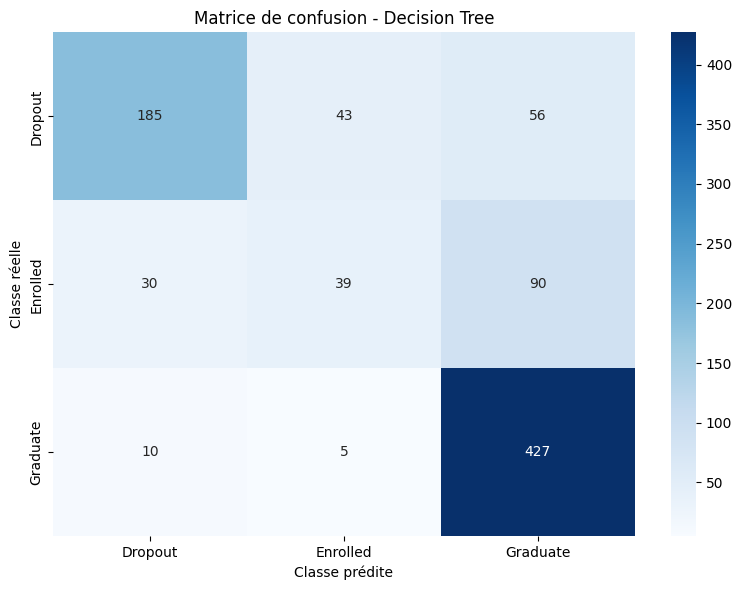

In [282]:
# Visualisation de la matrice de confusion
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matrice de confusion - Decision Tree")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()
plt.show()

### 3. Calcule de Precision, Recall et F1-score

In [283]:
metrics = []

# Calcul des métriques pour chaque classe
for classe in classes:

    TP = confusion_matrix.loc[classe, classe]
    FP = confusion_matrix[classe].sum() - TP
    FN = confusion_matrix.loc[classe].sum() - TP

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0

    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    metrics.append({
        "Classe": classe,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score
    })

metrics_df = pd.DataFrame(metrics)

display(metrics_df.round(4))

,Classe,Precision,Recall,F1-score
0,Dropout,0.8222,0.6514,0.7269
1,Enrolled,0.4483,0.2453,0.3171
2,Graduate,0.7452,0.9661,0.8414


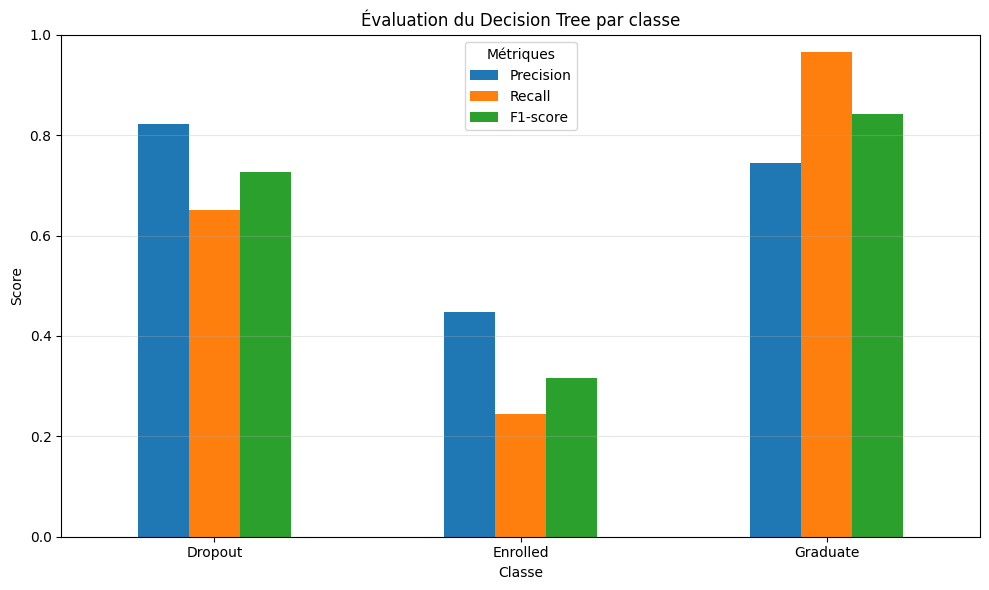

In [284]:
metrics_plot = metrics_df.set_index("Classe")

# Comparaison des métriques par classe
metrics_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Évaluation du Decision Tree par classe")
plt.xlabel("Classe")
plt.ylabel("Score")
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Importance des variables (Feature Importance)

L'objectif de cette étape est de mesurer la contribution de chaque variable dans la construction de l'arbre de décision.

À chaque nœud, l'arbre utilise une variable pour séparer les observations. Cette séparation produit une réduction de l'entropie mesurée par le gain d'information (Information Gain*).

Plus une variable contribue à des séparations importantes, plus son importance dans l'arbre est élevée.

Pour calculer cette importance, nous allons utiliser :
- Le gain d'information obtenu à chaque nœud.
- Le nombre d'observations présentes dans ce nœud.
- La contribution de chaque variable à l'ensemble des séparations.

Les importances seront ensuite normalisées afin que leur somme soit égale à 1.

**Remarque :** cette importance mesure la contribution des variables dans notre arbre construit. Elle ne représente pas une relation de causalité.

In [285]:
def calculate_feature_importance(tree, importances=None):


    # Initialiser le dictionnaire des importances
    if importances is None:
        importances = {}

    # Vérifier si le nœud est une feuille
    if "feature" not in tree:
        return importances

    # Récupérer les informations du nœud
    feature = tree["feature"]
    gain = tree["gain"]
    n_samples = tree["n_samples"]

    # Ajouter la contribution de la variable
    contribution = n_samples * gain

    importances[feature] = (
        importances.get(feature, 0) + contribution
    )

    # Parcourir récursivement la branche gauche
    calculate_feature_importance(tree["left"], importances)

    # Parcourir récursivement la branche droite
    calculate_feature_importance(tree["right"], importances)

    return importances

### Normalisation et classification des variables

In [286]:
# Calcul des importances
feature_importances = calculate_feature_importance(decision_tree)

# Calcul de la somme des contributions
total_importance = sum(feature_importances.values())

# Normalisation des importances
feature_importances = {
    feature: importance / total_importance
    for feature, importance in feature_importances.items()
}

# Création d'un DataFrame
importance_df = pd.DataFrame(
    list(feature_importances.items()),
    columns=["Feature", "Importance"]
)

# Trier les variables par ordre décroissant
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

,Feature,Importance
0,Curricular units 2nd sem (approved),0.692431
1,Tuition fees up to date,0.086512
2,Curricular units 1st sem (enrolled),0.062420
3,Curricular units 1st sem (evaluations),0.032556
4,Curricular units 2nd sem (evaluations),0.028123
5,Curricular units 2nd sem (grade),0.017850
6,Course,0.016835
7,GDP,0.015131
8,Curricular units 2nd sem (enrolled),0.012472
9,Curricular units 1st sem (approved),0.010934


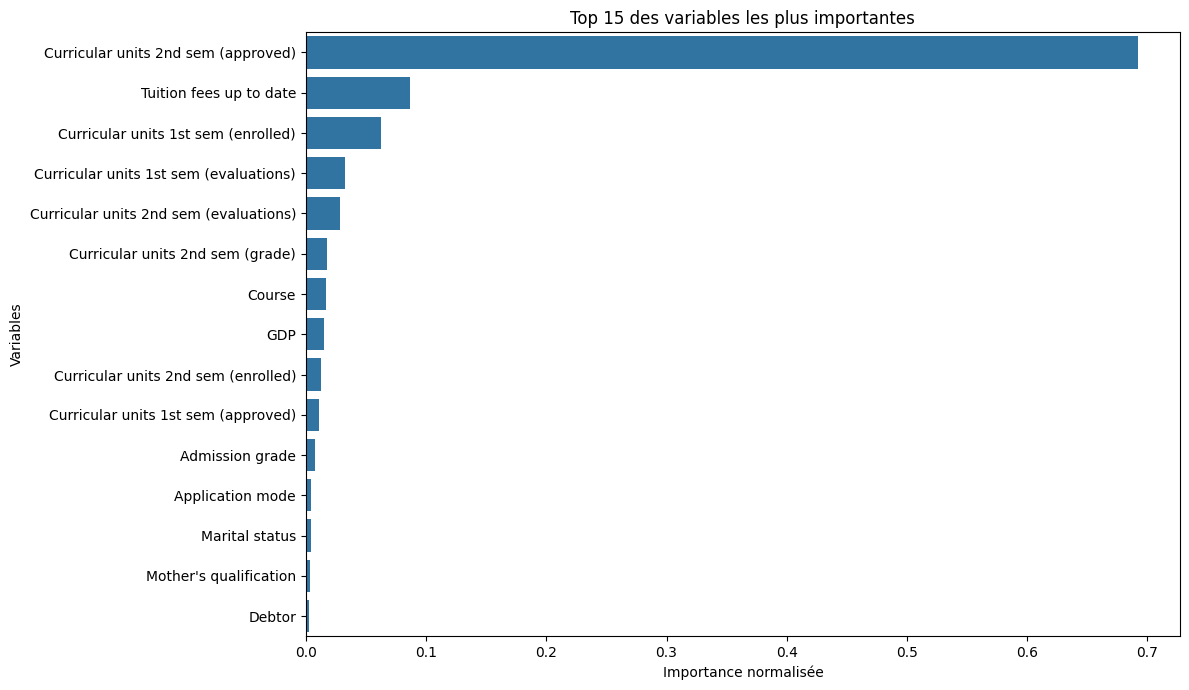

In [287]:
# Sélection des 15 variables les plus importantes
top_features = importance_df.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 des variables les plus importantes")
plt.xlabel("Importance normalisée")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

Pour visualise toutes les variables

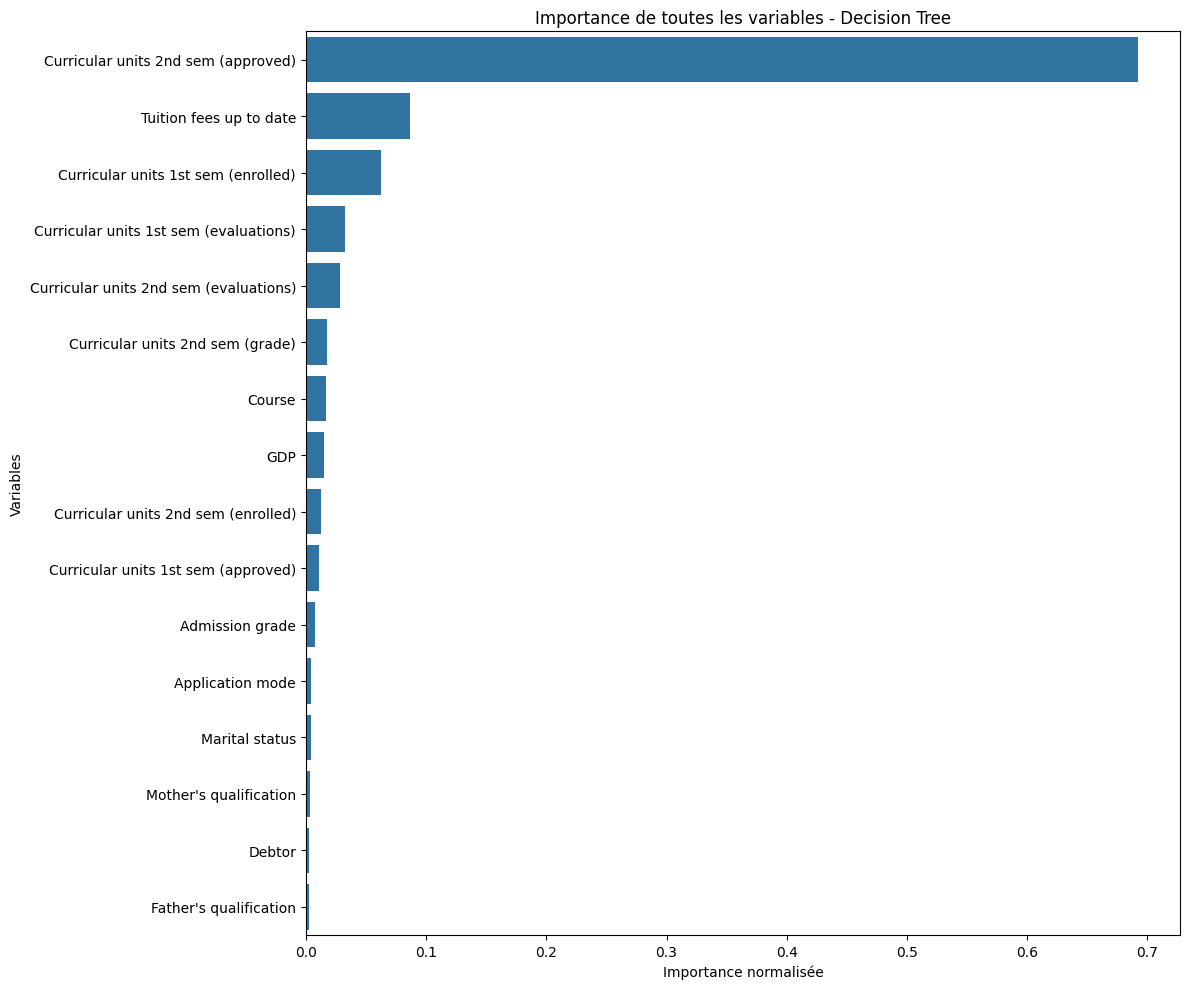

In [288]:
# Visualiser l'importance de toutes les variables
plt.figure(figsize=(12, 10))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Importance de toutes les variables - Decision Tree")
plt.xlabel("Importance normalisée")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

## Sélection des variables (Feature Selection)

On comparer plusieurs configurations :

- Les 5 variables les plus importantes.
- Les 10 variables les plus importantes.
- L'ensemble des variables disponibles.

Pour étudier l'influence du nombre de variables sur les performances du modèle et d'identifier un compromis entre simplicité et qualité de prédiction.

In [289]:
# Définir les différentes configurations de variables
top_5_features = importance_df["Feature"].head(5).tolist()

top_10_features = importance_df["Feature"].head(10).tolist()

all_features = X_train_tree.columns.tolist()

# Afficher les variables sélectionnées
print("Top 5 features :")
print(top_5_features)

print("\nTop 10 features :")
print(top_10_features)

print("\nNombre total de features :", len(all_features))

Top 5 features :
['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 2nd sem (evaluations)']

Top 10 features :
['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (grade)', 'Course', 'GDP', 'Curricular units 2nd sem (enrolled)', 'Curricular units 1st sem (approved)']

Nombre total de features : 36


On observe que les 5 prmières variables sont liées aux résultats et à l'activité académique des étudiants. Les 10 premières ajoutent notamment la note du deuxième semestre, le cursus (Course) et le PIB (GDP).

Pour faire une comparaison plus rigoureuse, nous allons diviser ce jeu d'entraînement en deux parties :
- Sous-ensemble d'entraînement : pour construire un nouvel arbre et calculer les importances.
- Validation : pour comparer les configurations Top 5, Top 10 et toutes les features.
Le jeu de test de 885 étudiants restera intact jusqu'à l'évaluation finale.

In [290]:
# Diviser les données d'entraînement en deux sous-ensembles
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_tree,
    y_train_tree,
    test_size=0.20,
    random_state=42,
    stratify=y_train_tree
)

print("Taille du sous-ensemble d'entraînement :", len(X_subtrain))
print("Taille du jeu de validation :", len(X_val))

Taille du sous-ensemble d'entraînement : 2831
Taille du jeu de validation : 708


In [291]:
# Construire un nouvel arbre uniquement sur le sous-ensemble d'entraînement
tree_selection = build_tree(
    X_subtrain,
    y_subtrain,
    categorical_cols,
    numerical_cols,
    max_depth=5,
    min_samples_split=20,
    min_gain=0.001
)

# Calculer les importances des variables
selection_importances = calculate_feature_importance(tree_selection)

# Normaliser les importances
total = sum(selection_importances.values())

selection_importances = {
    feature: value / total
    for feature, value in selection_importances.items()
}

# Créer le classement des variables
selection_df = pd.DataFrame(
    list(selection_importances.items()),
    columns=["Feature", "Importance"]
).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(selection_df)

KeyboardInterrupt: 

In [ ]:
# Sélectionner les 5 variables les plus importantes
top_5_features = selection_df["Feature"].head(5).tolist()

# Sélectionner les 10 variables les plus importantes
top_10_features = selection_df["Feature"].head(10).tolist()

# Conserver toutes les variables
all_features = X_subtrain.columns.tolist()

# Afficher les configurations
print("Top 5 :", top_5_features)
print("\nTop 10 :", top_10_features)
print("\nToutes les variables :", len(all_features))

Top 5 : ['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Course', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)']

Top 10 : ['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Course', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (enrolled)', 'Previous qualification (grade)', 'Admission grade', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (grade)']

Toutes les variables : 36


In [ ]:
# Regrouper les différentes configurations
feature_configurations = {
    "Top 5": top_5_features,
    "Top 10": top_10_features,
    "Toutes les features": all_features
}

# Préparer les variables catégorielles et numériques
config_types = {}

for name, features in feature_configurations.items():

    config_types[name] = {
        "categorical": [
            col for col in categorical_cols if col in features
        ],
        "numerical": [
            col for col in numerical_cols if col in features
        ]
    }

## Comparaison des configurations de variables

Afin d'évaluer l'influence de la sélection des variables sur les performances du modèle, nous allons comparer trois configurations : Top 5, Top 10 et l'ensemble des 36 variables.

Pour chaque configuration, un nouvel arbre de décision est construit uniquement à partir du sous-ensemble d'entraînement.

Les modèles sont ensuite évalués sur le même jeu de validation à l'aide des métriques suivantes :

- Accuracy.
- Recall de la classe Dropout.
- Recall de la classe Enrolled.
- F1-score macro.

Cette comparaison permettra d'identifier la configuration offrant le meilleur compromis entre réduction du nombre de variables et qualité de classification.

### A. Entraîner les trois arbres

In [ ]:
trees = {}

# Entraîner un arbre pour chaque configuration
for name, features in feature_configurations.items():

    print(f"Construction du modèle : {name}")

    # Récupérer les variables catégorielles et numériques
    categorical = config_types[name]["categorical"]
    numerical = config_types[name]["numerical"]

    # Sélectionner les variables correspondantes
    X_train_selected = X_subtrain[features]

    # Construire l'arbre
    trees[name] = build_tree(
        X_train_selected,
        y_subtrain,
        categorical,
        numerical,
        max_depth=5,
        min_samples_split=20,
        min_gain=0.001
    )

print("\nLes trois arbres ont été construits avec succès !")

Construction du modèle : Top 5
Construction du modèle : Top 10
Construction du modèle : Toutes les features

Les trois arbres ont été construits avec succès !


### B. Évaluer les trois arbres

In [ ]:
comparison_results = []

# Évaluer chaque arbre
for name, tree in trees.items():

    # Récupérer les variables de la configuration
    features = feature_configurations[name]

    # Préparer les données de validation
    X_val_selected = X_val[features]

    # Effectuer les prédictions
    predictions = predict(tree, X_val_selected)

    # Calculer l'accuracy
    accuracy = (predictions == y_val).mean()

    # Calculer les métriques pour chaque classe
    f1_scores = {}
    recalls = {}

    for classe in classes:

        TP = ((y_val == classe) & (predictions == classe)).sum()
        FP = ((y_val != classe) & (predictions == classe)).sum()
        FN = ((y_val == classe) & (predictions != classe)).sum()

        recall = TP / (TP + FN) if (TP + FN) > 0 else 0

        precision = TP / (TP + FP) if (TP + FP) > 0 else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) > 0 else 0
        )

        recalls[classe] = recall
        f1_scores[classe] = f1

    # Calcul du F1-score macro
    macro_f1 = np.mean(list(f1_scores.values()))

    # Enregistrer les résultats
    comparison_results.append({
        "Configuration": name,
        "Nombre de features": len(features),
        "Accuracy": accuracy,
        "Recall Dropout": recalls["Dropout"],
        "Recall Enrolled": recalls["Enrolled"],
        "F1-score Macro": macro_f1
    })

# Créer le tableau comparatif
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Configuration,Nombre de features,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,Top 5,5,0.7556,0.7048,0.2677,0.6572
1,Top 10,10,0.7458,0.7137,0.3937,0.6747
2,Toutes les features,36,0.7472,0.7137,0.4016,0.6775


### C . Visualiser la comparaison

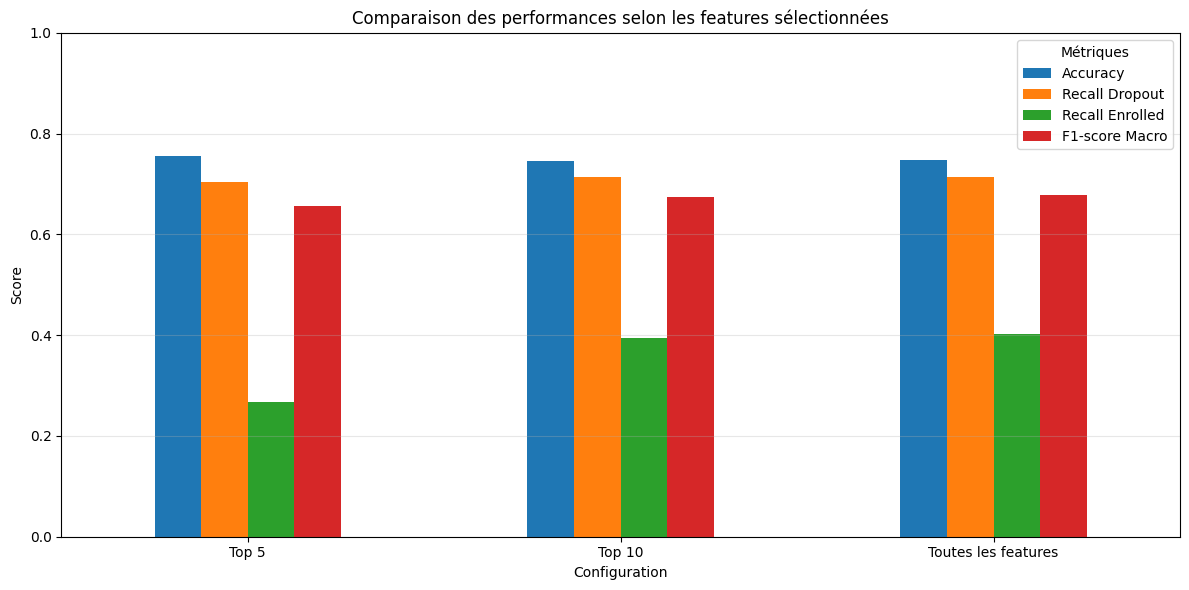

In [ ]:
comparison_plot = comparison_df.set_index("Configuration")[
    ["Accuracy", "Recall Dropout", "Recall Enrolled", "F1-score Macro"]
]

# Comparer les performances
comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparaison des performances selon les features sélectionnées")
plt.xlabel("Configuration")
plt.ylabel("Score")
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Analyse comparative des configurations

Trois configurations de variables ont été évaluées : Top 5, Top 10 et l'ensemble des 36 variables.

Les résultats montrent que la configuration Top 5 obtient la meilleure accuracy (75,56 %). Cependant, elle présente un faible rappel pour la classe Enrolled (26,77 %).

La configuration Top 10 améliore considérablement la reconnaissance de cette classe, avec un rappel de 39,37 %, tout en conservant une accuracy de 74,58 %.

L'utilisation des 36 variables permet d'obtenir le meilleur F1-score Macro (67,75 %), mais l'amélioration par rapport à Top 10 reste faible (0,28 point de pourcentage).

Ainsi, la configuration Top 10 représente un compromis intéressant entre réduction de la dimensionnalité et performances de classification.

Cette configuration sera conservée comme candidate pour les expérimentations comparatives avec les autres algorithmes d'apprentissage automatique.

## Optimisation des hyperparamètres (Hyperparameter Tuning)

Les hyperparamètres contrôlent la manière dont l'arbre de décision est construit. Leur choix influence directement sa complexité et ses performances de classification.

Nous allons étudier trois paramètres :

- **max_depth :** profondeur maximale autorisée pour l'arbre. Une profondeur trop importante peut provoquer du surapprentissage.
- **min_samples_split :** nombre minimal d'observations nécessaire pour diviser un nœud. Une valeur plus élevée limite les divisions sur de petits ensembles.
- **min_gain :** gain d'information minimal nécessaire pour accepter une séparation. Il permet d'éviter les divisions peu pertinentes.

Plusieurs combinaisons de ces paramètres seront testées sur le jeu d'entraînement et évaluées sur le jeu de validation.

Le jeu de test final ne sera pas utilisé pendant cette optimisation.

### 1. Préparation des données

In [ ]:
X_subtrain_10 = X_subtrain[top_10_features]
X_val_10 = X_val[top_10_features]

# Récupération des variables catégorielles et numériques
categorical_10 = [
    col for col in categorical_cols
    if col in top_10_features
]

numerical_10 = [
    col for col in numerical_cols
    if col in top_10_features
]

print("Nombre de variables :", len(top_10_features))
print("Variables catégorielles :", categorical_10)
print("Variables numériques :", numerical_10)

Nombre de variables : 10
Variables catégorielles : ['Course', 'Tuition fees up to date']
Variables numériques : ['Previous qualification (grade)', 'Admission grade', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']


### 2. Tester plusieurs combinaisons

In [ ]:
from itertools import product

# Définir les valeurs à tester
depth_values = [3, 5, 7]
min_samples_values = [20, 40]
gain_values = [0.001, 0.005]

# Stocker les résultats
tuning_results = []
tuning_trees = {}

# Tester toutes les combinaisons
for depth, min_samples, gain in product(
    depth_values,
    min_samples_values,
    gain_values
):

    # Construire l'arbre avec les paramètres actuels
    tree = build_tree(
        X_subtrain_10,
        y_subtrain,
        categorical_10,
        numerical_10,
        max_depth=depth,
        min_samples_split=min_samples,
        min_gain=gain
    )

    # Effectuer les prédictions sur le jeu de validation
    predictions = predict(tree, X_val_10)

    # Calculer l'accuracy
    accuracy = (predictions == y_val).mean()

    # Calculer les métriques par classe
    class_recalls = []
    class_f1_scores = []

    for classe in classes:

        # Calculer les vrais positifs, faux positifs et faux négatifs
        TP = ((y_val == classe) & (predictions == classe)).sum()
        FP = ((y_val != classe) & (predictions == classe)).sum()
        FN = ((y_val == classe) & (predictions != classe)).sum()

        # Calculer la précision
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0

        # Calculer le rappel
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0

        # Calculer le F1-score
        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) > 0 else 0
        )

        class_recalls.append(recall)
        class_f1_scores.append(f1)

    # Calculer le F1-score Macro
    macro_f1 = np.mean(class_f1_scores)

    # Enregistrer les résultats
    tuning_results.append({
        "Max depth": depth,
        "Min samples split": min_samples,
        "Min gain": gain,
        "Accuracy": accuracy,
        "Recall Dropout": class_recalls[0],
        "Recall Enrolled": class_recalls[1],
        "F1-score Macro": macro_f1
    })

    # Conserver l'arbre correspondant
    key = (depth, min_samples, gain)
    tuning_trees[key] = tree

# Créer le tableau des résultats
tuning_df = pd.DataFrame(tuning_results)

# Trier les configurations selon le F1-score Macro
tuning_df = tuning_df.sort_values(
    by="F1-score Macro",
    ascending=False
).reset_index(drop=True)

display(tuning_df.round(4))

,Max depth,Min samples split,Min gain,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,5,40,0.001,0.7514,0.7313,0.3937,0.6800
1,5,40,0.005,0.7514,0.7313,0.3937,0.6800
2,5,20,0.001,0.7458,0.7137,0.3937,0.6747
3,5,20,0.005,0.7458,0.7137,0.3937,0.6747
4,3,40,0.005,0.7387,0.7357,0.4094,0.6724
5,3,40,0.001,0.7387,0.7357,0.4094,0.6724
6,3,20,0.005,0.7387,0.7357,0.4094,0.6724
7,3,20,0.001,0.7387,0.7357,0.4094,0.6724
8,7,40,0.005,0.7415,0.7885,0.1811,0.6214
9,7,40,0.001,0.7415,0.7885,0.1811,0.6214


### 3. Visualisation des résultats

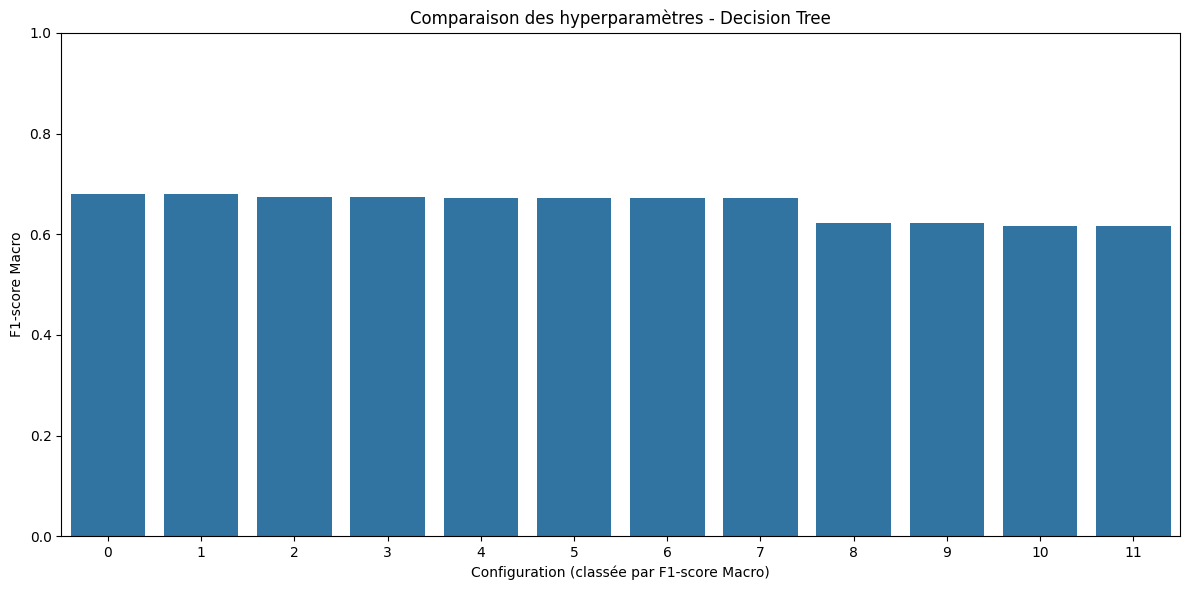

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=tuning_df,
    x=tuning_df.index.astype(str),
    y="F1-score Macro"
)

plt.title("Comparaison des hyperparamètres - Decision Tree")
plt.xlabel("Configuration (classée par F1-score Macro)")
plt.ylabel("F1-score Macro")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

### 4. Identifier la meilleur arbre

In [ ]:
# Récupérer la meilleure configuration
best_config = tuning_df.iloc[0]

best_params = (
    int(best_config["Max depth"]),
    int(best_config["Min samples split"]),
    float(best_config["Min gain"])
)

# Récupérer l'arbre correspondant
best_tree = tuning_trees[best_params]

print("Meilleurs hyperparamètres :")
print("Max depth :", best_params[0])
print("Min samples split :", best_params[1])
print("Min gain :", best_params[2])

print("\nMeilleur Accuracy :", round(best_config["Accuracy"], 4))
print("Meilleur F1-score Macro :", round(best_config["F1-score Macro"], 4))

Meilleurs hyperparamètres :
Max depth : 5
Min samples split : 40
Min gain : 0.001

Meilleur Accuracy : 0.7514
Meilleur F1-score Macro : 0.68


### Analyse de l'optimisation des hyperparamètres

Une recherche sur grille a été réalisée en faisant varier trois hyperparamètres : la profondeur maximale de l'arbre (max_depth), le nombre minimal d'observations nécessaire pour effectuer une division (min_samples_split) et le gain d'information minimal (min_gain).

Parmi les 12 configurations testées, la meilleure configuration est obtenue avec :

- max_depth = 5
- min_samples_split = 40
- min_gain = 0.001

Elle atteint une accuracy de 75,14 % et un F1-score Macro de 0,6800 sur le jeu de validation.

Les arbres de profondeur 7 présentent une diminution du F1-score Macro, principalement en raison de leur faible capacité à reconnaître la classe Enrolled.

La configuration retenue constitue donc le meilleur compromis parmi les configurations testées, selon le F1-score Macro.

## Le modèle final

### A. Construire l'arbre final

In [ ]:
X_train_final = X_train_tree[top_10_features]
X_test_final = X_test_tree[top_10_features]

# Construire l'arbre final sur toutes les données d'entraînement
final_tree = build_tree(
    X_train_final,
    y_train_tree,
    categorical_10,
    numerical_10,
    max_depth=5,
    min_samples_split=40,
    min_gain=0.001
)

print("Arbre de décision final construit avec succès !")
print("Nombre de variables :", len(top_10_features))
print("Nombre d'observations d'entraînement :", len(X_train_final))

Arbre de décision final construit avec succès !
Nombre de variables : 10
Nombre d'observations d'entraînement : 3539


### B. Effectuer les prédictions sur le jeu de test

In [ ]:
# Prédire les classes des étudiants du jeu de test
y_pred_final = predict(final_tree, X_test_final)

print("Premières prédictions :")
print(y_pred_final.head(10))

print("\nClasses réelles :")
print(y_test_tree.head(10))

Premières prédictions :
1853    Graduate
2399    Graduate
510      Dropout
242     Graduate
3392    Graduate
1787    Graduate
1158    Graduate
260     Graduate
1852    Graduate
1191    Graduate
dtype: str

Classes réelles :
1853    Graduate
2399    Graduate
510     Enrolled
242     Graduate
3392    Graduate
1787    Graduate
1158    Graduate
260     Graduate
1852    Graduate
1191    Graduate
Name: Target, dtype: str


### C. Évaluer les performances finales

Accuracy finale : 0.7458
Accuracy en pourcentage : 74.58 %


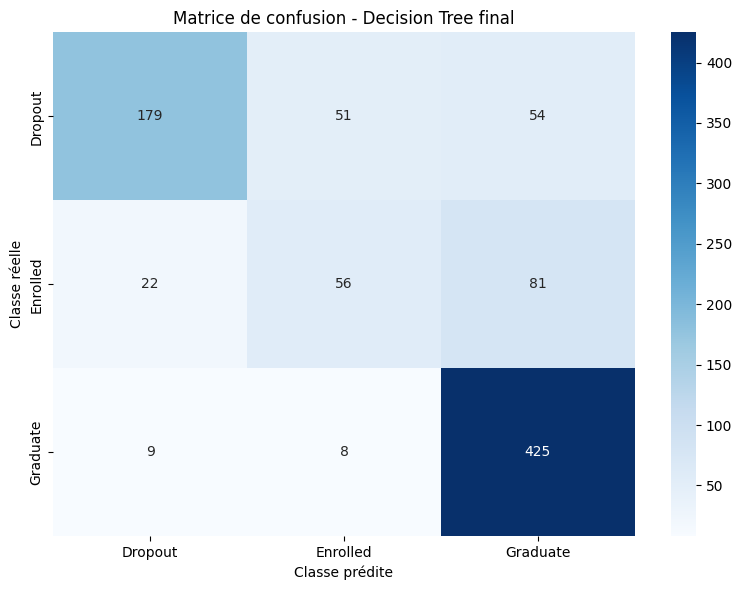

In [ ]:
# Calculer l'accuracy finale
accuracy_final = (y_pred_final == y_test_tree).mean()

print("Accuracy finale :", round(accuracy_final, 4))
print("Accuracy en pourcentage :", round(accuracy_final * 100, 2), "%")

# Construire la matrice de confusion
classes_final = sorted(y_test_tree.unique())

matrice_finale = pd.crosstab(
    y_test_tree,
    y_pred_final,
    rownames=["Classe réelle"],
    colnames=["Classe prédite"],
    dropna=False
).reindex(
    index=classes_final,
    columns=classes_final,
    fill_value=0
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matrice_finale,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matrice de confusion - Decision Tree final")
plt.tight_layout()
plt.show()

### Évaluation finale du Decision Tree

Après la sélection des 10 variables les plus pertinentes et l'optimisation des hyperparamètres, le modèle final a été entraîné sur l'ensemble des données d'entraînement, puis évalué sur le jeu de test contenant 885 observations.

Le modèle obtient une accuracy de 74,58 %, soit 660 prédictions correctes sur 885 observations.

L'analyse par classe révèle des performances différentes :

- **Dropout :** le modèle obtient une précision de 85,24 % et un rappel de 63,03 %.
- **Enrolled :** cette classe présente les performances les plus faibles, avec un rappel de 35,22 %.
- **Graduate :** le modèle obtient un rappel élevé de 96,15 %, ce qui montre sa bonne capacité à identifier les étudiants ayant terminé leur formation avec succès.

Ces résultats montrent que le modèle reconnaît particulièrement bien la classe Graduate, mais rencontre davantage de difficultés pour distinguer les étudiants Enrolled des autres catégories.

La matrice de confusion met notamment en évidence les confusions entre Enrolled et Graduate, ainsi qu'entre Dropout et les deux autres classes.

Malgré une accuracy globale satisfaisante, l'amélioration de la reconnaissance des classes minoritaires constitue une piste d'amélioration importante.

## Amélioration de la reconnaissance de Enrolled

### Examination de la distribution des classes

,Nombre d'étudiants,Pourcentage
Target,,
Graduate,1767,49.93
Dropout,1137,32.13
Enrolled,635,17.94


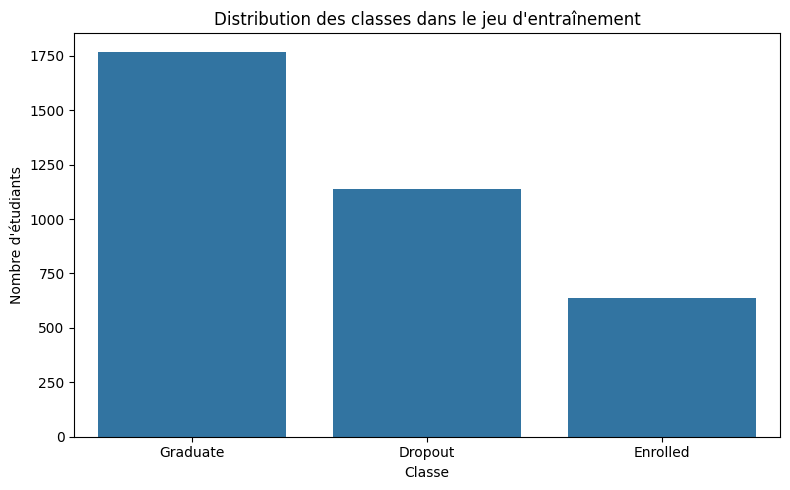

In [ ]:
# Examiner la distribution des classes dans les données d'entraînement
distribution_train = y_train_tree.value_counts().to_frame(
    name="Nombre d'étudiants"
)

distribution_train["Pourcentage"] = (
    y_train_tree.value_counts(normalize=True) * 100
).round(2)

display(distribution_train)

# Visualiser la distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y_train_tree,
    order=y_train_tree.value_counts().index
)

plt.title("Distribution des classes dans le jeu d'entraînement")
plt.xlabel("Classe")
plt.ylabel("Nombre d'étudiants")

plt.tight_layout()
plt.show()

In [ ]:
# Comparer la distribution des classes
distribution_comparaison = pd.DataFrame({
    "Entraînement": y_train_tree.value_counts(normalize=True) * 100,
    "Test": y_test_tree.value_counts(normalize=True) * 100
}).round(2)

display(distribution_comparaison)

,Entraînement,Test
Target,,
Graduate,49.93,49.94
Dropout,32.13,32.09
Enrolled,17.94,17.97


In [ ]:
# Comparer les variables numériques selon la classe
for col in numerical_10:

    print(f"\n--- {col} ---")

    statistiques = df.loc[
        X_train_tree.index
    ].groupby(y_train_tree)[col].agg(
        ["mean", "median", "std"]
    )

    display(statistiques.round(2))


--- Previous qualification (grade) ---


,mean,median,std
Target,,,
Dropout,131.04,133.1,12.93
Enrolled,131.62,131.0,12.96
Graduate,134.13,133.1,13.31



--- Admission grade ---


,mean,median,std
Target,,,
Dropout,124.81,123.3,15.37
Enrolled,125.49,123.9,13.92
Graduate,128.70,127.3,13.95



--- Curricular units 1st sem (evaluations) ---


,mean,median,std
Target,,,
Dropout,7.75,8.0,4.99
Enrolled,9.45,9.0,3.50
Graduate,8.22,8.0,3.74


... (6 outputs left out)


--- Curricular units 2nd sem (approved) ---


,mean,median,std
Target,,,
Dropout,1.94,0.0,2.62
Enrolled,4.10,4.0,2.19
Graduate,6.16,6.0,2.28



--- Curricular units 2nd sem (grade) ---


,mean,median,std
Target,,,
Dropout,5.84,0.0,6.12
Enrolled,11.15,12.0,3.56
Graduate,12.67,13.0,2.75


In [ ]:
# Comparer les variables catégorielles selon la classe
for col in categorical_10:

    print(f"\n--- {col} ---")

    repartition = pd.crosstab(
        X_train_tree[col],
        y_train_tree,
        normalize="columns"
    ) * 100

    display(repartition.round(2))


--- Course ---


Target,Dropout,Enrolled,Graduate
Course,,,
33,0.62,0.31,0.06
171,5.89,4.25,4.58
8014,4.66,2.83,5.32
9003,5.89,4.88,4.13
9070,3.43,5.04,5.83
9085,6.95,9.92,7.64
9119,5.98,8.35,0.68
9130,5.63,2.52,1.98
9147,9.59,14.33,5.77



--- Tuition fees up to date ---


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,32.01,5.35,1.19
1,67.99,94.65,98.81


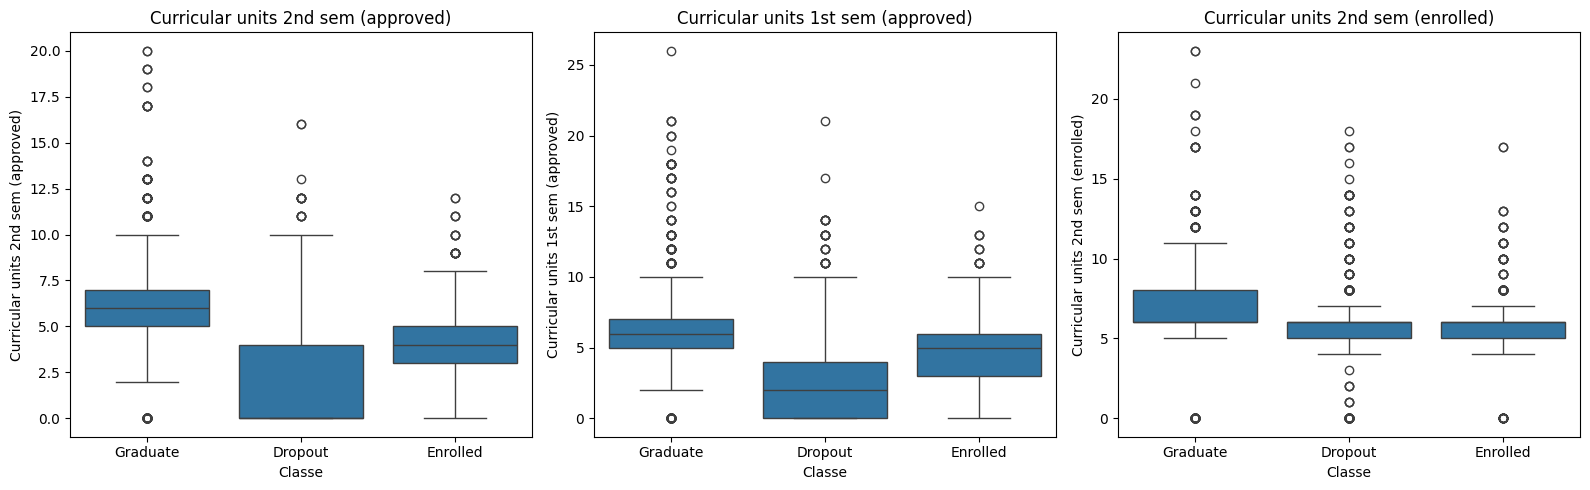

In [ ]:
# Comparer les principales variables selon Target
features_a_analyser = [
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (enrolled)"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, features_a_analyser):

    sns.boxplot(
        x=y_train_tree,
        y=X_train_tree[col],
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Classe")

plt.tight_layout()
plt.show()

## Arbre de décision pondéré

Dans cette partie, nous allons améliorer l'arbre de décision classique
en prenant en compte le déséquilibre des classes.

La classe Enrolled est minoritaire par rapport à Graduate et Dropout.
Nous allons donc attribuer un poids plus important aux observations
appartenant aux classes minoritaires.

L'objectif est de comparer les performances de l'arbre classique
avec celles de l'arbre pondéré.

### 8.1 Déséquilibre des classes

La variable cible `Target` contient trois classes :

- `Graduate` : 49,93 %
- `Dropout` : 32,12 %
- `Enrolled` : 17,95 %

La classe `Enrolled` est donc la classe minoritaire.

Un arbre classique peut avoir tendance à favoriser les classes majoritaires.
La pondération permet de donner davantage d'importance aux erreurs
commises sur les classes minoritaires.

### 8.2 Calcul des poids des classes

Nous attribuons à chaque classe un poids inversement proportionnel
à sa fréquence dans les données.

La formule utilisée est :

$$
w_c = \frac{N}{K \times N_c}
$$

avec :

- $N$ : nombre total d'observations ;
- $K$ : nombre de classes ;
- $N_c$ : nombre d'observations appartenant à la classe $c$.

Ainsi, une classe moins représentée reçoit un poids plus important.

In [ ]:
# Calculer le poids de chaque classe
nombre_classes = y_train_tree.nunique()
nombre_observations = len(y_train_tree)

effectifs_classes = y_train_tree.value_counts()

poids_classes = {}

for classe, effectif in effectifs_classes.items():

    poids = nombre_observations / (
        nombre_classes * effectif
    )

    poids_classes[classe] = poids

print("Poids attribués aux classes :")

for classe, poids in poids_classes.items():
    print(f"{classe} : {poids:.4f}")

Poids attribués aux classes :
Graduate : 0.6676
Dropout : 1.0375
Enrolled : 1.8577


In [ ]:
# Poids attribués aux différentes classes
print(poids_classes)

{'Graduate': 0.6676098849273722, 'Dropout': 1.0375256523013778, 'Enrolled': 1.857742782152231}


### 8.3 Entropie pondérée

L'entropie pondérée tient compte du poids attribué à chaque classe pour mesurer l'impureté d'un nœud.

In [ ]:
def weighted_entropy(y, poids_classes):
    # Si le nœud est vide
    if len(y) == 0:
        return 0

    # Calcul du poids total du nœud
    poids_total = sum(poids_classes[classe] for classe in y)

    entropie = 0

    # Parcours des classes présentes dans le nœud
    for classe in y.unique():

        # Nombre d'observations de cette classe
        effectif = (y == classe).sum()

        # Poids total de cette classe
        poids_classe = effectif * poids_classes[classe]

        # Probabilité pondérée
        probabilite = poids_classe / poids_total

        if probabilite > 0:
            entropie -= probabilite * np.log2(probabilite)

    return entropie

In [ ]:
entropie_ponderee = weighted_entropy(
    y_train_tree,
    poids_classes
)

print("Entropie pondérée :", entropie_ponderee)

Entropie pondérée : 1.584962500721156


### 8.4 Gain d'information pondéré

Le gain d'information mesure la qualité d'une séparation.

Avec les poids des classes, on utilise l'entropie pondérée pour favoriser
la bonne classification des classes minoritaires.

In [ ]:
def weighted_information_gain(y, left_y, right_y, poids_classes):

    # Entropie pondérée du nœud parent
    entropie_parent = weighted_entropy(y, poids_classes)

    # Poids total du parent
    poids_parent = sum(poids_classes[classe] for classe in y)

    # Poids des deux branches
    poids_gauche = sum(poids_classes[classe] for classe in left_y)
    poids_droite = sum(poids_classes[classe] for classe in right_y)

    # Vérifier que les branches ne sont pas vides
    if poids_gauche == 0 or poids_droite == 0:
        return 0

    # Proportions pondérées
    proportion_gauche = poids_gauche / poids_parent
    proportion_droite = poids_droite / poids_parent

    # Entropies des deux branches
    entropie_gauche = weighted_entropy(left_y, poids_classes)
    entropie_droite = weighted_entropy(right_y, poids_classes)

    # Gain d'information pondéré
    gain = entropie_parent - (
        proportion_gauche * entropie_gauche
        + proportion_droite * entropie_droite
    )

    return gain

### 8.5 Recherche de la meilleure séparation

La fonction teste les différentes valeurs des variables catégorielles et les seuils des variables numériques, puis sélectionne la séparation qui maximise le gain pondéré.

In [ ]:
def weighted_best_split(X, y, categorical_features,
                        numerical_features, poids_classes):

    best_gain = -1
    best_feature = None
    best_split_value = None
    best_split_type = None

    # Tester les variables catégorielles
    for feature in categorical_features:

        values = X[feature].dropna().unique()

        for value in values:

            left_mask = X[feature] == value
            right_mask = X[feature] != value

            left_y = y.loc[left_mask]
            right_y = y.loc[right_mask]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            gain = weighted_information_gain(
                y, left_y, right_y, poids_classes
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = value
                best_split_type = "categorical"

    # Tester les variables numériques
    for feature in numerical_features:

        values = np.sort(X[feature].dropna().unique())

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left_mask = X[feature] <= threshold
            right_mask = X[feature] > threshold

            left_y = y.loc[left_mask]
            right_y = y.loc[right_mask]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            gain = weighted_information_gain(
                y, left_y, right_y, poids_classes
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_split_value = threshold
                best_split_type = "numerical"

    return best_feature, best_split_value, best_split_type, best_gain

### 8.6 Classe majoritaire pondérée

La classe prédite dans une feuille est celle qui possède le poids total le plus élevé.

In [ ]:
def weighted_majority_class(y, poids_classes):

    poids_par_classe = {}

    for classe in y.unique():

        effectif = (y == classe).sum()

        poids_par_classe[classe] = (
            effectif * poids_classes[classe]
        )

    return max(poids_par_classe, key=poids_par_classe.get)

### 8.7 Construction de l'arbre pondéré

L'arbre est construit récursivement en utilisant le gain d'information pondéré et la classe majoritaire pondérée.

In [ ]:
def build_weighted_tree(X, y, categorical_features, numerical_features,
                        poids_classes, depth=0, max_depth=5,
                        min_samples_split=40, min_gain=0.001):

    # Déterminer la classe majoritaire pondérée
    prediction = weighted_majority_class(y, poids_classes)

    # Arrêter si le nœud est pur
    if y.nunique() == 1:
        return {"prediction": prediction}

    # Arrêter si la profondeur maximale est atteinte
    if depth >= max_depth:
        return {"prediction": prediction}

    # Arrêter si le nombre d'observations est insuffisant
    if len(y) < min_samples_split:
        return {"prediction": prediction}

    # Rechercher la meilleure séparation pondérée
    feature, split_value, split_type, gain = weighted_best_split(
        X, y, categorical_features, numerical_features, poids_classes
    )

    # Arrêter si aucune séparation pertinente n'est trouvée
    if feature is None or gain <= min_gain:
        return {"prediction": prediction}

    # Créer les deux branches
    if split_type == "numerical":
        left_mask = X[feature] <= split_value
        right_mask = X[feature] > split_value

    else:
        left_mask = X[feature] == split_value
        right_mask = X[feature] != split_value

    # Éviter les branches vides
    if not left_mask.any() or not right_mask.any():
        return {"prediction": prediction}

    # Construire récursivement les deux sous-arbres
    left_subtree = build_weighted_tree(
        X.loc[left_mask],
        y.loc[left_mask],
        categorical_features,
        numerical_features,
        poids_classes,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    right_subtree = build_weighted_tree(
        X.loc[right_mask],
        y.loc[right_mask],
        categorical_features,
        numerical_features,
        poids_classes,
        depth + 1,
        max_depth,
        min_samples_split,
        min_gain
    )

    # Retourner le nœud
    return {
        "feature": feature,
        "split_value": split_value,
        "split_type": split_type,
        "gain": gain,
        "n_samples": len(y),
        "left": left_subtree,
        "right": right_subtree,
        "prediction": prediction
    }

### 8.8 Entraînement de l'arbre pondéré

Nous construisons l'arbre avec les mêmes variables et les mêmes hyperparamètres que l'arbre classique afin de comparer l'effet de la pondération.

In [ ]:
# Construire l'arbre pondéré
weighted_tree = build_weighted_tree(
    X_train_final,
    y_train_tree,
    categorical_10,
    numerical_10,
    poids_classes,
    max_depth=5,
    min_samples_split=40,
    min_gain=0.001
)

print("Arbre pondéré construit avec succès !")

Arbre pondéré construit avec succès !


### 8.9 Prédiction et évaluation

Nous appliquons l'arbre pondéré au jeu de test, puis nous évaluons ses performances à l'aide des mêmes métriques que l'arbre classique.

In [ ]:
# Prédictions sur le jeu de test
y_pred_weighted = predict(weighted_tree, X_test_final)

print("Premières prédictions :")
print(y_pred_weighted.head(10))

print("\nClasses réelles :")
print(y_test_tree.head(10))

Premières prédictions :
1853    Graduate
2399    Enrolled
510      Dropout
242     Graduate
3392    Graduate
1787    Enrolled
1158    Enrolled
260     Enrolled
1852    Graduate
1191    Enrolled
dtype: str

Classes réelles :
1853    Graduate
2399    Graduate
510     Enrolled
242     Graduate
3392    Graduate
1787    Graduate
1158    Graduate
260     Graduate
1852    Graduate
1191    Graduate
Name: Target, dtype: str


### Accuracy et matrice de confusion

In [ ]:
# Calcul de l'accuracy
accuracy_weighted = (y_pred_weighted == y_test_tree).mean()

print(f"Accuracy pondérée : {accuracy_weighted:.4f}")
print(f"Accuracy en pourcentage : {accuracy_weighted * 100:.2f}%")

# Construire la matrice de confusion
matrice_ponderee = pd.crosstab(
    y_test_tree,
    y_pred_weighted,
    rownames=["Classe réelle"],
    colnames=["Classe prédite"],
    dropna=False
).reindex(
    index=classes,
    columns=classes,
    fill_value=0
)

display(matrice_ponderee)

Accuracy pondérée : 0.6554
Accuracy en pourcentage : 65.54%


Classe prédite,Dropout,Enrolled,Graduate
Classe réelle,,,
Dropout,181,79,24
Enrolled,27,108,24
Graduate,11,140,291


In [ ]:
metrics_weighted = []

for classe in classes:

    TP = matrice_ponderee.loc[classe, classe]
    FP = matrice_ponderee[classe].sum() - TP
    FN = matrice_ponderee.loc[classe].sum() - TP

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1_score = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    metrics_weighted.append({
        "Classe": classe,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score
    })

metrics_weighted_df = pd.DataFrame(metrics_weighted)

display(metrics_weighted_df.round(4))

,Classe,Precision,Recall,F1-score
0,Dropout,0.8265,0.6373,0.7197
1,Enrolled,0.3303,0.6792,0.4444
2,Graduate,0.8584,0.6584,0.7452


### 8.10 Comparaison entre l'arbre classique et l'arbre pondéré

Nous comparons les deux modèles sur le même jeu de test afin d'évaluer l'impact de la pondération sur la reconnaissance des différentes classes.

In [ ]:
# Calculer le F1-score macro des deux modèles
f1_macro_classique = metrics_df["F1-score"].mean()
f1_macro_pondere = metrics_weighted_df["F1-score"].mean()

# Construire le tableau comparatif
comparaison_arbres = pd.DataFrame({
    "Modèle": ["Arbre classique", "Arbre pondéré"],
    "Accuracy": [accuracy_final, accuracy_weighted],
    "Recall Dropout": [
        metrics_df.loc[
            metrics_df["Classe"] == "Dropout", "Recall"
        ].iloc[0],
        metrics_weighted_df.loc[
            metrics_weighted_df["Classe"] == "Dropout", "Recall"
        ].iloc[0]
    ],
    "Recall Enrolled": [
        metrics_df.loc[
            metrics_df["Classe"] == "Enrolled", "Recall"
        ].iloc[0],
        metrics_weighted_df.loc[
            metrics_weighted_df["Classe"] == "Enrolled", "Recall"
        ].iloc[0]
    ],
    "F1-score Macro": [
        f1_macro_classique,
        f1_macro_pondere
    ]
})

display(comparaison_arbres.round(4))

,Modèle,Accuracy,Recall Dropout,Recall Enrolled,F1-score Macro
0,Arbre classique,0.7458,0.6514,0.2453,0.6285
1,Arbre pondéré,0.6554,0.6373,0.6792,0.6364


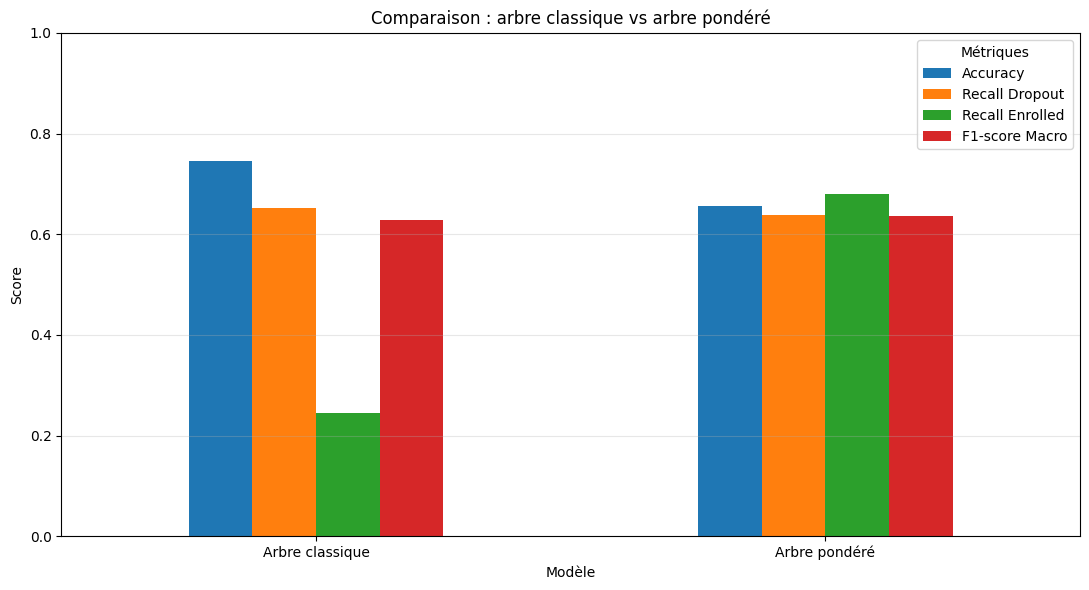

In [ ]:
# Visualiser la comparaison des performances
comparaison_plot = comparaison_arbres.set_index("Modèle")

comparaison_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparaison : arbre classique vs arbre pondéré")
plt.xlabel("Modèle")
plt.ylabel("Score")
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Comparaison entre l'arbre de décision classique et l'arbre pondéré

L'objectif de cette comparaison est d'évaluer l'effet de la pondération des classes sur les performances du modèle, notamment sur la détection de la classe minoritaire `Enrolled`.

#### 1. Comparaison des performances globales

| Modèle | Accuracy | Recall Dropout | Recall Enrolled | F1-score Macro |
|:---|---:|---:|---:|---:|
| Arbre classique | **74.58 %** | 65.14 % | 24.53 % | 62.85 % |
| Arbre pondéré | 65.54 % | 63.73 % | **67.92 %** | **63.64 %** |

#### 2. Analyse des résultats

- **Accuracy :** l'arbre classique obtient une meilleure accuracy (74.58 % contre 65.54 %). Il réalise donc davantage de prédictions correctes sur l'ensemble du jeu de test.
- **Recall Dropout :** les deux modèles présentent des performances proches (65.14 % et 63.73 %).
- **Recall Enrolled :** l'arbre pondéré améliore considérablement la détection de cette classe, passant de 24.53 % à 67.92 %. La pondération permet ainsi de mieux prendre en compte la classe minoritaire.
- **F1-score Macro :** l'arbre pondéré obtient un score légèrement supérieur (63.64 % contre 62.85 %), indiquant un meilleur équilibre global entre les classes.

#### 3. Interprétation

La pondération des classes modifie le comportement de l'arbre de décision. En accordant davantage d'importance aux classes minoritaires pendant l'apprentissage, le modèle pondéré améliore leur détection, particulièrement celle de la classe `Enrolled`.

Cependant, cette amélioration s'accompagne d'une diminution de l'accuracy et d'une précision relativement faible pour la classe `Enrolled` (33.03 %). Cela signifie que le modèle identifie davantage d'étudiants réellement inscrits, mais produit également plus de fausses prédictions dans cette catégorie.

#### 4. Conclusion

Les deux modèles présentent des avantages différents :

- **Arbre classique :** meilleure performance globale en termes d'accuracy.
- **Arbre pondéré :** meilleure détection de la classe minoritaire et meilleur F1-score Macro.

Dans le contexte de la prédiction du décrochage et de la réussite académique, l'arbre pondéré constitue une alternative intéressante lorsque l'objectif est d'améliorer la détection des différentes catégories d'étudiants, plutôt que de maximiser uniquement l'accuracy.

La sélection finale du modèle dépend donc de la priorité donnée à chaque métrique et du coût associé aux erreurs de classification.


Exportation des données

In [ ]:
import joblib
import os

# Créer le dossier de sortie
os.makedirs("outputs", exist_ok=True)

# Ajouter la variable cible aux données préparées
train_final = X_train_encoded.copy()
train_final["Target"] = y_train

test_final = X_test_encoded.copy()
test_final["Target"] = y_test

# Exporter les jeux de données
train_final.to_csv("outputs/train_processed.csv", index=False)
test_final.to_csv("outputs/test_processed.csv", index=False)

# Sauvegarder le scaler utilisé
joblib.dump(scaler, "outputs/scaler.pkl")

print("Exportation terminée !")

Exportation terminée !
